In [1]:
import pandas as pd

# Ember

In [106]:
df = pd.read_csv("yearly_full_release_long_format.csv")

In [117]:
df["full_variable_name"] = df["Category"] + "_" + df["Subcategory"] + "_" + df["Variable"]
df["full_variable_name"] = df["full_variable_name"].str.lower().str.replace(" ", "_")
df["full_variable_name"] = df["full_variable_name"].str.lower().str.replace(",", "")
df["full_variable_name"].sample(n=10)

46636     electricity_generation_fuel_other_renewables
235020               electricity_generation_fuel_hydro
50424               capacity_aggregate_fuel_renewables
157841               electricity_generation_fuel_hydro
31401              electricity_generation_fuel_nuclear
180832                power_sector_emissions_fuel_wind
84562                electricity_generation_fuel_hydro
211999               electricity_generation_fuel_solar
154634               electricity_generation_fuel_solar
128542    electricity_generation_fuel_other_renewables
Name: full_variable_name, dtype: object

In [129]:
country = "USA"
df.query("`Country code` == @country").query("Category == 'Electricity generation' & `Unit` == 'TWh'")["Subcategory"].unique()

array(['Aggregate fuel', 'Fuel', 'Total'], dtype=object)

In [136]:
gen = df.query("Category == 'Electricity generation' & `Subcategory` == 'Fuel' & `Unit` == 'TWh'")
gen

,Area,Country code,Year,Area type,Continent,Ember region,EU,OECD,G20,G7,ASEAN,Category,Subcategory,Variable,Unit,Value,YoY absolute change,YoY % change,full_variable_name
38,Afghanistan,AFG,2000,Country,Asia,Asia,0.0,0.0,0.0,0.0,0.0,Electricity generation,Fuel,Bioenergy,TWh,0.00,NaN,NaN,electricity_generation_fuel_bioenergy
39,Afghanistan,AFG,2000,Country,Asia,Asia,0.0,0.0,0.0,0.0,0.0,Electricity generation,Fuel,Coal,TWh,0.00,NaN,NaN,electricity_generation_fuel_coal
40,Afghanistan,AFG,2000,Country,Asia,Asia,0.0,0.0,0.0,0.0,0.0,Electricity generation,Fuel,Gas,TWh,0.00,NaN,NaN,electricity_generation_fuel_gas
41,Afghanistan,AFG,2000,Country,Asia,Asia,0.0,0.0,0.0,0.0,0.0,Electricity generation,Fuel,Hydro,TWh,0.31,NaN,NaN,electricity_generation_fuel_hydro
42,Afghanistan,AFG,2000,Country,Asia,Asia,0.0,0.0,0.0,0.0,0.0,Electricity generation,Fuel,Nuclear,TWh,0.00,NaN,NaN,electricity_generation_fuel_nuclear
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
331822,Zimbabwe,ZWE,2021,Country,Africa,Africa,0.0,0.0,0.0,0.0,0.0,Electricity generation,Fuel,Nuclear,TWh,0.00,0.00,NaN,electricity_generation_fuel_nuclear
331823,Zimbabwe,ZWE,2021,Country,Africa,Africa,0.0,0.0,0.0,0.0,0.0,Electricity generation,Fuel,Other Fossil,TWh,0.04,0.00,0.00,electricity_generation_fuel_other_fossil
331824,Zimbabwe,ZWE,2021,Country,Africa,Africa,0.0,0.0,0.0,0.0,0.0,Electricity generation,Fuel,Other Renewables,TWh,0.00,0.00,NaN,electricity_generation_fuel_other_renewables
331825,Zimbabwe,ZWE,2021,Country,Africa,Africa,0.0,0.0,0.0,0.0,0.0,Electricity generation,Fuel,Solar,TWh,0.04,0.01,33.33,electricity_generation_fuel_solar


In [154]:
import chart_studio.plotly as py
import plotly.graph_objects as go
import plotly

def plot_area_generation(generation: pd.DataFrame, area:str, area_col:str, fuel_type_col:str, date_col: str, gen_col: str, publish=False, local=True):
    area_generation = generation[generation[area_col] == area].copy()

    traces = []

    for fuel_type in generation[fuel_type_col].unique():
        fuel_type_net_gen = area_generation[area_generation[fuel_type_col] == fuel_type]
        formated_generation = (fuel_type_net_gen[gen_col]).round(decimals=0).astype("Int64")
        traces.append(go.Scatter(
            x=fuel_type_net_gen[date_col],
            y=formated_generation,
            stackgroup="one",
            name=fuel_type,
            marker_colorscale=plotly.colors.sequential.Viridis,
        ))

    fig = go.Figure(data=traces)
    # fig.update_layout(showlegend=False)
    fig.update_layout(legend=dict(
        yanchor="top",
        y=0.99,
        xanchor="left",
        x=0.01
    ))
    fig.update_layout(
        margin=dict(l=20, r=20, t=20, b=20),
    )
    fig.update_layout({
    # "plot_bgcolor": "rgba(0, 0, 0, 0)",
    "paper_bgcolor": "rgba(0, 0, 0, 0)",
    })
    fig.update_layout(
        xaxis_title="Years",
        yaxis_title="Gigawatt Hours (Gwh)",
        hovermode='x',
        yaxis_tickformat=",.2r"
    )
    if local:
        fig.show()
    if publish:
        py.plot(fig, filename = f"{area.lower()}_electricity_generation", auto_open=False)


39                               Chad
146                       New Zealand
10                              ASEAN
71                             France
22                              Benin
210    Turks and Caicos Islands (the)
13                            Austria
3                             Algeria
198        Syrian Arab Republic (the)
195                          Suriname
dtype: object

Mexico


Jamaica


United States of America


Lebanon


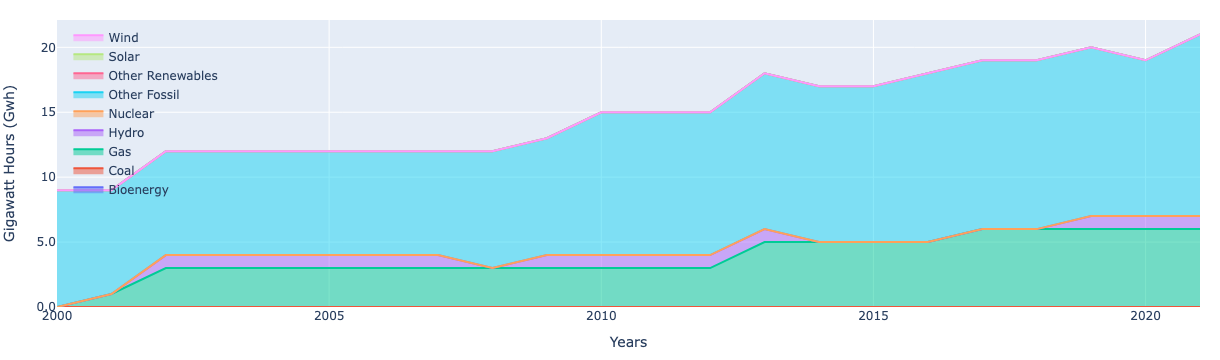

Barbados


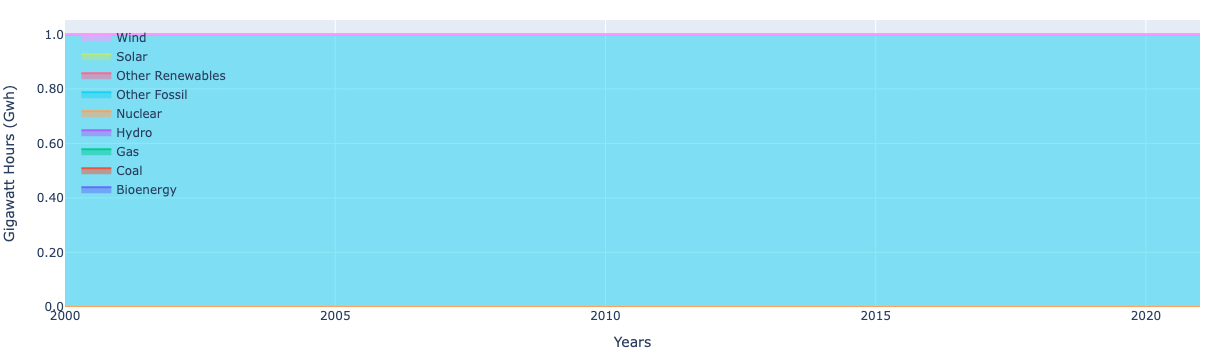

Egypt


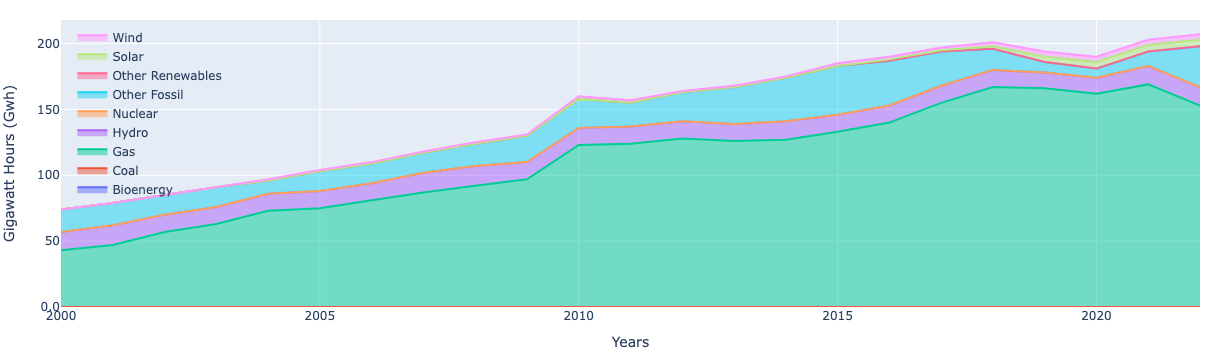

South Korea


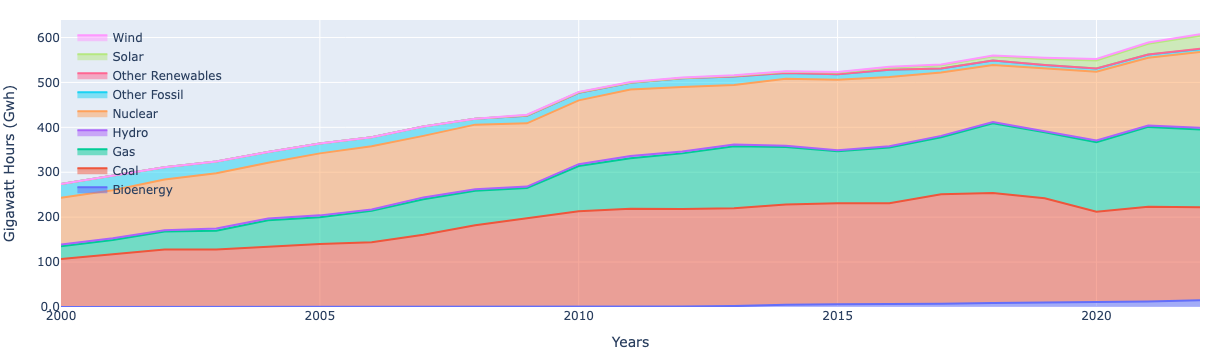

India


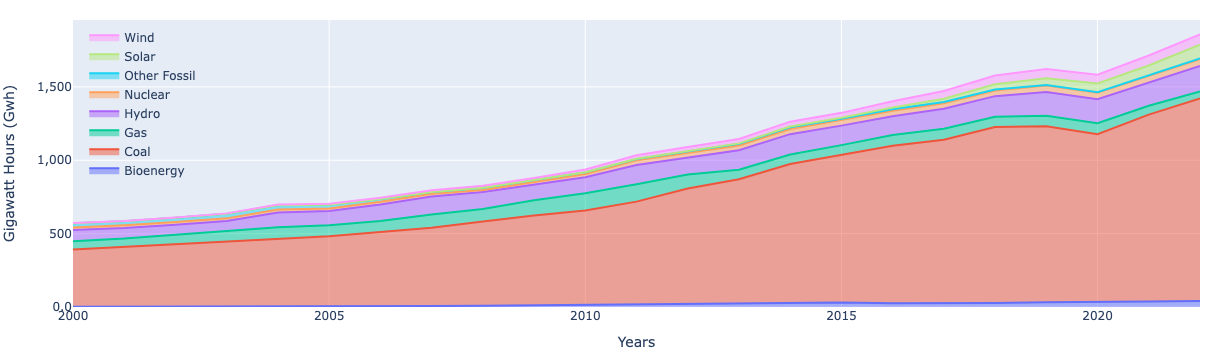

Guinea-Bissau


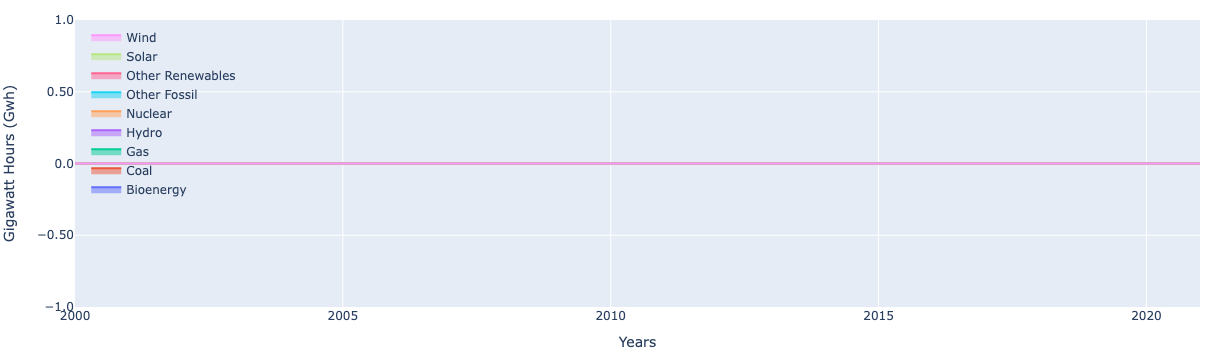

G7


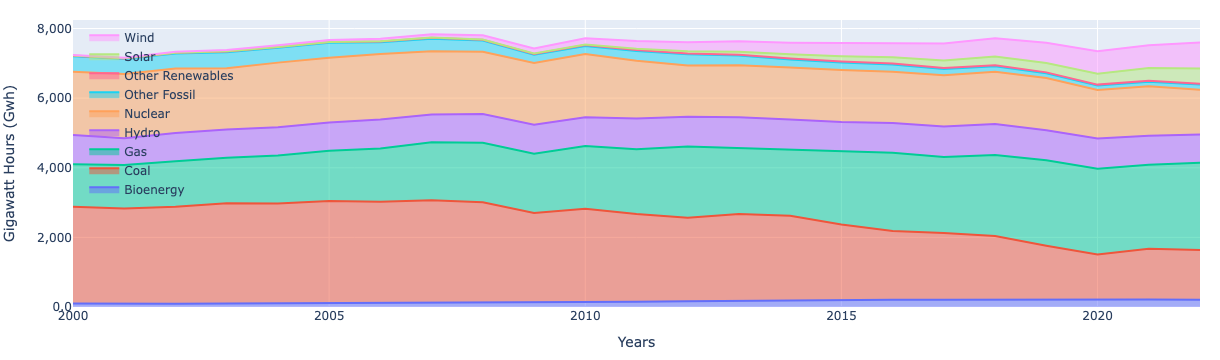

In [168]:
for country in pd.Series(gen["Area"].unique()).sample(n=10):
    print(country)
    plot_area_generation(gen, area=country, area_col="Area", fuel_type_col="Variable", date_col="Year", gen_col="Value", publish=False, local=True)

In [123]:
df.pivot(columns=["Area", "full_variable_name"], values=["Value"])

/var/folders/ts/zf71sqq50nx4d41fy5xtsxhw0000gn/T/ipykernel_93004/874621103.py:1: PerformanceWarning: The following operation may generate 3829834686 cells in the resulting pandas object.
  df.pivot(columns=["Area", "full_variable_name"], values=["Value"])


Value  \
Area                                 Afghanistan   
full_variable_name capacity_aggregate_fuel_clean   
0                                           0.19   
1                                            NaN   
2                                            NaN   
3                                            NaN   
4                                            NaN   
...                                          ...   
331841                                       NaN   
331842                                       NaN   
331843                                       NaN   
331844                                       NaN   
331845                                       NaN   

                                                   \
Area                                                
full_variable_name capacity_aggregate_fuel_fossil   
0                                             NaN   
1                                            0.03   
2                                             NaN   
3                                             NaN   
4                                             NaN   
...                                           ...   
331841                                        NaN   
331842                                        NaN   
331843                                        NaN   
331844                                        NaN   
331845                                        NaN   

                                                                 \
Area                                                              
full_variable_name capacity_aggregate_fuel_gas_and_other_fossil   
0                                                           NaN   
1                                                           NaN   
2                                                          0.03   
3                                                           NaN   
4                                                           NaN   
...                                                         ...   
331841                                                      NaN   
331842                                                      NaN   
331843                                                      NaN   
331844                                                      NaN   
331845                                                      NaN   

                                                                                 \
Area                                                                              
full_variable_name capacity_aggregate_fuel_hydro_bioenergy_and_other_renewables   
0                                                                 NaN             
1                                                                 NaN             
2                                                                 NaN             
3                                                                0.19             
4                                                                 NaN             
...                                                               ...             
331841                                                            NaN             
331842                                                            NaN             
331843                                                            NaN             
331844                                                            NaN             
331845                                                            NaN             

                                                       \
Area                                                    
full_variable_name capacity_aggregate_fuel_renewables   
0                                                 NaN   
1                                                 NaN   
2                                                 NaN   
3                                                 NaN   
4                                                0.19   
...          

In [ ]:
df